In [1]:
import matplotlib.pyplot as plt
import numpy as np

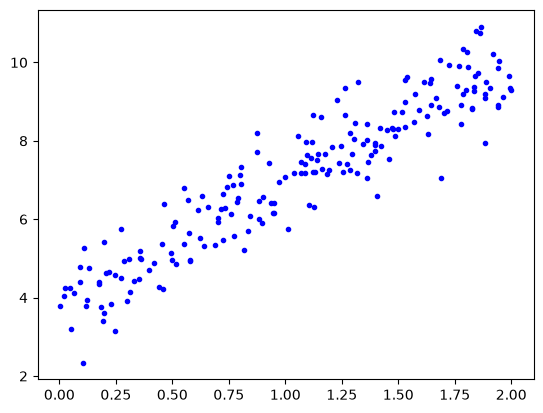

In [2]:
np.random.seed(24)
m = 200 #Number of examples
n = 1 #Number of features
X = 2 * np.random.rand(m,n)
Y = 4 + 3*X + 0.7*np.random.randn(m,1)
#real_Y = 4 + 3*X
plt.plot(X,Y,"b.")
#plt.plot(X,real_Y,"r")
plt.show()

In [3]:
m_2 = 200 # Numero esempi
n_2 = 1 # Numero features (valori in input della funzione)
X_2 = np.random.rand(m_2,n_2) # Vettore "Numero esempi" * "Numero features" => 20*1
print(X_2)

[[0.01934165]
 [0.18345392]
 [0.33177861]
 [0.17617143]
 [0.23704825]
 [0.64087291]
 [0.48507762]
 [0.83296729]
 [0.45256802]
 [0.26550269]
 [0.32071404]
 [0.70507318]
 [0.26539995]
 [0.78524858]
 [0.87905181]
 [0.0267808 ]
 [0.02730316]
 [0.01031339]
 [0.92751079]
 [0.04548879]
 [0.53025406]
 [0.11572938]
 [0.30842843]
 [0.72395218]
 [0.5574466 ]
 [0.27830423]
 [0.68308332]
 [0.8930561 ]
 [0.41729933]
 [0.92504363]
 [0.29577162]
 [0.12073912]
 [0.45390769]
 [0.76893908]
 [0.93816299]
 [0.63546394]
 [0.98587876]
 [0.20362429]
 [0.28969192]
 [0.74246391]
 [0.12690526]
 [0.33326395]
 [0.48231998]
 [0.77021879]
 [0.16322819]
 [0.94038063]
 [0.81508387]
 [0.3618031 ]
 [0.87194419]
 [0.21059268]
 [0.60523085]
 [0.63547643]
 [0.91693483]
 [0.14940091]
 [0.42203651]
 [0.69568106]
 [0.32603326]
 [0.03068941]
 [0.66218485]
 [0.06922663]
 [0.21719061]
 [0.58802137]
 [0.09889886]
 [0.85850198]
 [0.77293699]
 [0.48019532]
 [0.06579228]
 [0.58111298]
 [0.20828542]
 [0.4175705 ]
 [0.93876031]
 [0.22

In [4]:
# Creazione di un vettore contenente i valori Y con annesso rumore dovuto ad una distribuzione Gaussiana => 0.5* np.random.randn(m_2,1)
Y_2 = 3 + 8*X_2 + 0.5* np.random.randn(m_2,1)
print(Y_2)

real_Y_2 = 3 + 8*X_2
#Check per verificare che corrisponda con MSE calcolato sotto per theta0 = 0 e theta1 = 1
temp_sum = 0
for elem in Y_2:
    temp_sum += elem
print(temp_sum/len(Y_2))    

[[ 3.09151197]
 [ 4.72803985]
 [ 5.19638679]
 [ 4.27671376]
 [ 5.37428705]
 [ 8.04207252]
 [ 7.10738795]
 [10.20869055]
 [ 6.34042783]
 [ 5.99453975]
 [ 4.57375014]
 [ 8.22459158]
 [ 5.6684145 ]
 [ 9.80129318]
 [ 9.67671068]
 [ 2.3620632 ]
 [ 3.55380722]
 [ 3.22394454]
 [ 9.98811703]
 [ 3.47236952]
 [ 7.65657303]
 [ 3.32578801]
 [ 4.72849026]
 [ 8.95875974]
 [ 7.80846622]
 [ 6.51353749]
 [ 8.24833646]
 [10.90750816]
 [ 6.54464361]
 [10.60277971]
 [ 5.67595466]
 [ 4.41573515]
 [ 6.42650155]
 [ 9.22875868]
 [10.56897271]
 [ 7.24430933]
 [11.69634651]
 [ 4.79224685]
 [ 4.72083991]
 [ 9.18809136]
 [ 3.25251479]
 [ 5.28938374]
 [ 6.80736049]
 [ 9.63605717]
 [ 4.78504077]
 [10.60245848]
 [ 9.63579445]
 [ 5.78522737]
 [10.55256927]
 [ 4.88131285]
 [ 8.00550424]
 [ 8.04594194]
 [10.20109107]
 [ 4.65500708]
 [ 6.56053969]
 [ 8.48297401]
 [ 4.908525  ]
 [ 3.446063  ]
 [ 8.75006846]
 [ 2.98447471]
 [ 3.60146989]
 [ 7.86423461]
 [ 3.76888849]
 [ 9.9158929 ]
 [ 9.4506433 ]
 [ 7.48734157]
 [ 3.04442

<function matplotlib.pyplot.show(close=None, block=None)>

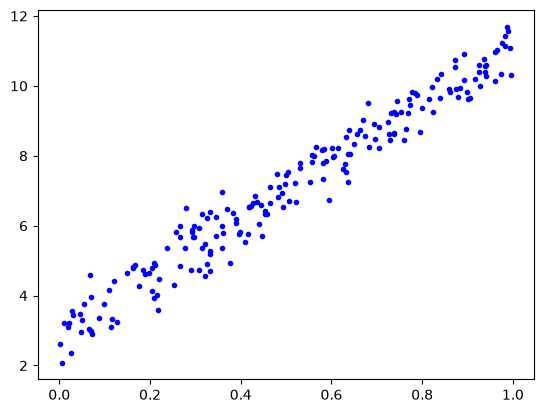

In [5]:
plt.plot(X_2,Y_2,"b.")
plt.show

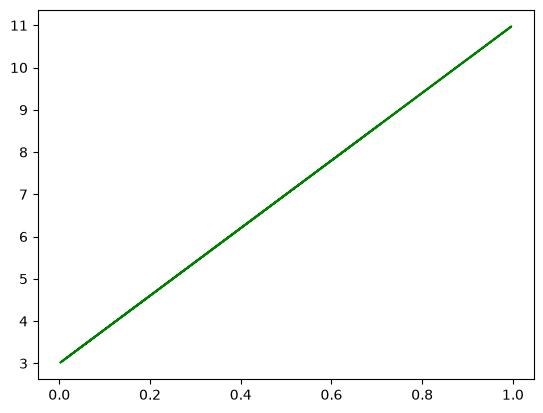

In [6]:
# Funzione Y senza alcun rumore
real_Y_2 = 3 + 8* X_2
plt.plot(X_2,real_Y_2,"g")

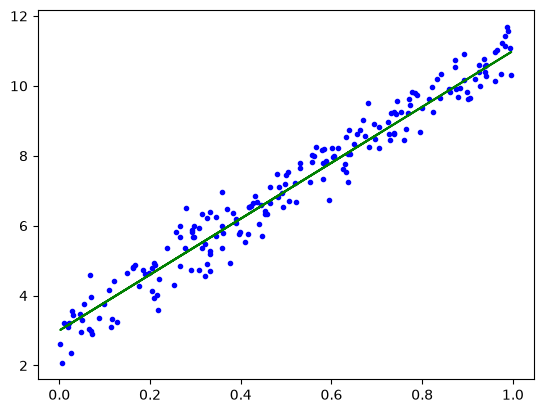

In [7]:
# Grafico finale con funzione originale (in verde) e i punti da approssimare (in blu)
plt.plot(X_2,Y_2,"b.")
plt.plot(X_2,real_Y_2,"g")
plt.show()

Step risolutivi per approssimare i dati sintetici tramite regressione lineare
1) Scegliere due punti iniziali $\theta_0$ e $\theta_1$ => $\theta_0$ + $\theta_1$ * X_2 
2) Calcolare la loss tramite MSE rispetto ad ogni punto reale
3) Gradient Descent
4) Ripetere il passaggio precedente finchè l'errore non sarà minimo
   

In [8]:
#Parametri inziali (entrambi 0 oppure randomici)
theta0 = 0
theta1 = 0

In [9]:
#Calcolo della Loss
def MSE(theta0,theta1,X,Y):
    cost_sum = 0
    for i in range(len(X)):
        cost_sum += ((theta0 + theta1 * X[i]) - Y[i]) ** 2
    return cost_sum/len(X)    

In [10]:
MSE(theta0,theta1,X_2,Y_2)

array([56.1849266])

In [11]:
def theta0_derivative(theta0,theta1,X,Y):
    cost_sum = 0
    for i in range(len(X)):
        cost_sum += (theta0 + theta1 * X[i]) - Y[i]
    return (2 * cost_sum)/len(X)

def theta1_derivative(theta0,theta1,X,Y):
    cost_sum = 0
    for i in range(len(X)):
        cost_sum += ((theta0 + theta1 * X[i]) - Y[i]) * X[i]
    return (2 * cost_sum)/len(X)

#Gradient Descent
def gradient_descent(old_theta0,old_theta1,lr,X,Y):
    new_theta0 = old_theta0 - lr * theta0_derivative(old_theta0,old_theta1,X,Y)
    new_theta1 = old_theta1 - lr * theta1_derivative(old_theta0,old_theta1,X,Y)
    return new_theta0, new_theta1


In [12]:
lr = 0.01
x,y = gradient_descent(theta0,theta1,lr,X,Y)

In [13]:
#Il gradiente viene calcolato più volte finchè l'errore non raggiungerà un valore molto piccolo

def train(theta0,theta1,lr,X,Y):
    epsilon = 1e-8 # Errore accettato
    
    current_theta0 = theta0
    current_theta1 = theta1
    
    prev_loss = MSE(current_theta0, current_theta1, X, Y)
    print(prev_loss)
    
    current_theta0, current_theta1 = gradient_descent(current_theta0, current_theta1, lr, X, Y)
    current_loss = MSE(current_theta0, current_theta1, X, Y)
    
    while( abs(prev_loss - current_loss) > epsilon):
        prev_loss = current_loss
        current_theta0, current_theta1 = gradient_descent(current_theta0, current_theta1, lr, X, Y)
        current_loss = MSE(current_theta0, current_theta1, X, Y)
        
    print(f"I valori ottimizzati sono rispettivamente: theta0 => {current_theta0} e theta1 => {current_theta1}")
    print(f"Loss finale: {current_loss}")

    return [current_theta0, current_theta1]

In [14]:
trained_theta0, trained_theta1 = train(theta0, theta1, lr, X_2, Y_2)

[56.1849266]
I valori ottimizzati sono rispettivamente: theta0 => [2.94836587] e theta1 => [8.17977019]
Loss finale: [0.22875514]


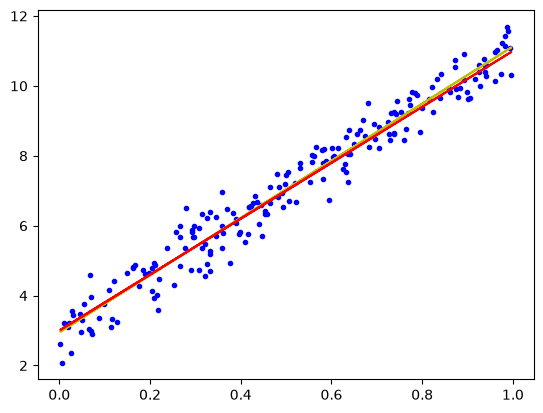

In [15]:
plt.plot(X_2,Y_2,"b.")

trained_Y = trained_theta0 + trained_theta1 * X_2

plt.plot(X_2,trained_Y, "y")
plt.plot(X_2,real_Y_2, "r") 
plt.show()